# Split figé, preprocessing et extraction de features

**Projet ForestFireDetection** – Détection précoce de feux de forêt (fumée / feu)
Objectifs :
1. **Figer le découpage train / val / test** avant toute transformation (comme dans le P7).
2. Préparer les images (RGB, redimensionnement, normalisation) avec **le même pipeline pour les 3 splits**.
3. Extraire un vecteur de features par image avec **ResNet50 pré-entraîné sur ImageNet** (gelé).

Entrée : `data/processed/metadata.csv` (produit par `data_exploration.ipynb`).

## 1. Imports

In [ ]:
import sys
import time
from pathlib import Path

# Ajout de la racine du projet au chemin Python pour importer src/
ROOT = Path.cwd().resolve()
sys.path.append(str(ROOT.parent if ROOT.name == "notebooks" else ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

## 2. Configuration

Chemins, constantes et matériel centralisés dans `src/config.py`.
Le GPU est **obligatoire** : sans GPU CUDA, l'import lève une erreur explicite.

In [ ]:
from src.config import (
    ROOT_DIR, PROCESSED_DIR, FEATURES_DIR, METADATA_PATH, BOXES_PATH, SPLITS_PATH,
    CATEGORY_ORDER, RANDOM_STATE, IMG_SIZE, IMAGENET_MEAN, IMAGENET_STD,
    DEVICE, BATCH_SIZE, NUM_WORKERS, PIN_MEMORY, PERSISTENT_WORKERS, describe_device,
)
from src.datasets import DFireDataset

describe_device()

# Paramètres propres à ce notebook
VAL_FOLDS = 5              # 1 pli sur 5 -> 20 % du train pour la validation
DUP_THRESHOLD = 4          # Distance de Hamming max (dHash 64 bits) pour parler de quasi-doublon

PyTorch 2.14.1+cu130 | appareil : cuda
GPU : NVIDIA GeForce RTX 5070 Laptop GPU | mémoire : 7.9 Go
DataLoader : batch 64, 0 workers, pin_memory=True, décodage JPEG réduit=True


## 3. Chargement des métadonnées de l'exploration (`data_exploration.ipynb`)

In [ ]:
# dhash lu comme texte pour conserver les zéros de tête
df = pd.read_csv(METADATA_PATH, dtype={"dhash": str})
boxes = pd.read_csv(BOXES_PATH)
print(f"Images : {len(df)} | boîtes : {len(boxes)}")
print(df["split"].value_counts())

Images : 21527 | boîtes : 26557
split
train    17221
test      4306
Name: count, dtype: int64


## 4. Nettoyage des labels au niveau image

Le modèle prédit deux labels binaires par image : **fumée oui/non** et **feu oui/non**.
Les boîtes ne servent qu'à dériver ces labels :
- les **boîtes d'aire nulle** (18) ne représentent aucun objet → retirées avant de recalculer les labels ;
- les **boîtes hors [0, 1]** (8) n'ont pas d'impact ici (seule la présence de la classe compte).
  Elles seraient à corriger (clipping) uniquement pour un modèle de détection.

In [ ]:
valid_boxes = boxes[boxes["area"] > 0]

# Recalcul des labels binaires à partir des boîtes valides uniquement
presence = valid_boxes.pivot_table(index="image_id", columns="class_name",
                                   values="area", aggfunc="size", fill_value=0)
has_smoke_new = df["image_id"].map(presence["smoke"] > 0).fillna(False).astype(int)
has_fire_new = df["image_id"].map(presence["fire"] > 0).fillna(False).astype(int)

changed = (has_smoke_new != df["has_smoke"]) | (has_fire_new != df["has_fire"])
print(f"Images dont le label change : {changed.sum()}")
display(df.loc[changed, ["image_id", "split", "has_smoke", "has_fire"]]
          .assign(has_smoke_new=has_smoke_new[changed], has_fire_new=has_fire_new[changed]))

df["has_smoke"], df["has_fire"] = has_smoke_new, has_fire_new


def to_category(smoke, fire):
    """Catégorie image (4 classes) à partir des deux labels binaires."""
    if smoke and fire:
        return "fire_and_smoke"
    if fire:
        return "fire_only"
    if smoke:
        return "smoke_only"
    return "none"


df["category"] = [to_category(s, f) for s, f in zip(df["has_smoke"], df["has_fire"])]

Images dont le label change : 0


,image_id,split,has_smoke,has_fire,has_smoke_new,has_fire_new


## 5. Groupes de quasi-doublons

L'exploration a montré que beaucoup d'images `AoF` sont des images successives d'une même caméra.
Si deux images quasi identiques sont l'une en train et l'autre en val, la validation est trop optimiste.

Méthode :
- deux images sont **voisines** si la distance de Hamming entre leurs dHash est ≤ `DUP_THRESHOLD` ;
- un **groupe** = ensemble d'images reliées entre elles (composante connexe du graphe des voisins).

Choix du seuil (4) : sur les paires inspectées visuellement, celles à distance ≤ 4 sont indiscernables ; au-delà,
on trouve surtout la même caméra fixe à d'autres moments, et les groupes deviennent énormes
(une seule composante de plusieurs milliers d'images dès 6–8).

In [ ]:
hashes = np.array([int(h, 2) for h in df["dhash"]], dtype=np.uint64)   # 64 bits par image


def neighbor_pairs(h_a, h_b, threshold, chunk=1000):
    """Paires (i, j) avec distance de Hamming(h_a[i], h_b[j]) <= threshold, calcul par blocs."""
    rows, cols = [], []
    for start in range(0, len(h_a), chunk):
        dist = np.bitwise_count(h_a[start:start + chunk, None] ^ h_b[None, :])  # XOR puis nb de bits à 1
        r, c = np.nonzero(dist <= threshold)
        rows.append(r + start)
        cols.append(c)
    return np.concatenate(rows), np.concatenate(cols)


# Groupes calculés sur le train officiel uniquement (le test reste à part)
train_idx = np.flatnonzero(df["split"] == "train")
r, c = neighbor_pairs(hashes[train_idx], hashes[train_idx], DUP_THRESHOLD)
graph = coo_matrix((np.ones(len(r)), (r, c)), shape=(len(train_idx), len(train_idx)))
n_groups, group_labels = connected_components(graph, directed=False)

df["group_id"] = -1
df.loc[train_idx, "group_id"] = group_labels
group_sizes = np.bincount(group_labels)
print(f"Images train : {len(train_idx)} | groupes : {n_groups}")
print(f"Groupes de taille 1 : {(group_sizes == 1).sum()} | plus gros groupe : {group_sizes.max()} images")

Images train : 17221 | groupes : 9593
Groupes de taille 1 : 8856 | plus gros groupe : 849 images


## 6. Découpage train / val (figé)

- `StratifiedGroupKFold` (scikit-learn) : **stratifié** sur la catégorie image et **groupé** par quasi-doublons.
- On garde **un pli sur 5** comme validation (≈ 20 % du train officiel).
- Le test officiel D-Fire est conservé tel quel.

D'après la doc scikit-learn, la stratification est respectée « as much as possible » quand il y a des
groupes : on vérifie donc les proportions juste après.

In [ ]:
df_train = df.iloc[train_idx]
sgkf = StratifiedGroupKFold(n_splits=VAL_FOLDS, shuffle=True, random_state=RANDOM_STATE)
_, val_pos = next(sgkf.split(df_train, y=df_train["category"], groups=df_train["group_id"]))

df["final_split"] = df["split"]                                   # "train" ou "test"
df.loc[df_train.index[val_pos], "final_split"] = "val"

# Contrôle : aucun groupe partagé entre train et val
groups_train = set(df.loc[df["final_split"] == "train", "group_id"])
groups_val = set(df.loc[df["final_split"] == "val", "group_id"])
print(f"Groupes communs train/val : {len(groups_train & groups_val)}")
print(df["final_split"].value_counts().reindex(["train", "val", "test"]))

Groupes communs train/val : 0
final_split
train    13773
val       3448
test      4306
Name: count, dtype: int64


In [ ]:
# Contrôle de la stratification : proportions par catégorie dans chaque split
props = (pd.crosstab(df["category"], df["final_split"], normalize="columns")
           .reindex(index=CATEGORY_ORDER, columns=["train", "val", "test"]) * 100)
display(props.round(1).rename(columns=lambda s: f"{s} (%)"))
display(df.groupby("final_split")[["has_smoke", "has_fire"]].mean().mul(100).round(1)
          .reindex(["train", "val", "test"]).rename(columns={"has_smoke": "fumée (%)", "has_fire": "feu (%)"}))

final_split,train (%),val (%),test (%)
category,,,
smoke_only,27.2,27.1,27.5
fire_only,5.4,5.6,5.1
fire_and_smoke,21.9,21.8,20.8
none,45.5,45.4,46.6


,fumée (%),feu (%)
final_split,,
train,49.1,27.3
val,49.0,27.4
test,48.3,25.9


## 7. Sous-ensemble « test propre »

Le test officiel contient des quasi-doublons d'images du train (cf. exploration). On le garde intact
pour rester comparable aux autres travaux sur D-Fire, mais on marque les images de test **sans aucun
voisin** (distance ≤ `DUP_THRESHOLD`) dans train + val. Les métriques seront rapportées sur les deux :
**test complet** et **test propre** (estimation plus honnête de la généralisation).

In [ ]:
test_idx = np.flatnonzero(df["split"] == "test")
r_t, _ = neighbor_pairs(hashes[test_idx], hashes[train_idx], DUP_THRESHOLD)

df["test_clean"] = False
df.loc[test_idx, "test_clean"] = True
df.loc[test_idx[np.unique(r_t)], "test_clean"] = False     # a au moins un voisin dans le train officiel

n_clean = df["test_clean"].sum()
print(f"Test complet : {len(test_idx)} | test propre : {n_clean} ({n_clean / len(test_idx):.1%})")
display(pd.crosstab(df.loc[test_idx, "category"], df.loc[test_idx, "test_clean"])
          .reindex(CATEGORY_ORDER).rename(columns={True: "propre", False: "avec voisin train"}))
display(pd.crosstab(df.loc[test_idx, "source"], df.loc[test_idx, "test_clean"])
          .rename(columns={True: "propre", False: "avec voisin train"}))

Test complet : 4306 | test propre : 2192 (50.9%)


test_clean,avec voisin train,propre
category,,
smoke_only,580,606
fire_only,121,99
fire_and_smoke,208,687
none,1205,800


test_clean,avec voisin train,propre
source,,
AoF,1537,124
PublicDataset,136,145
WEB,441,1923


**Limite connue** : les caméras fixes `AoF` produisent des images très semblables même à des jours
différents (distance > 4). Le test propre retire les quasi-doublons, pas la similarité « même caméra ».

## 8. Sauvegarde du découpage (figé)

Ce fichier est **la référence** pour toutes les étapes suivantes : on ne redécoupe plus jamais.

In [ ]:
split_cols = ["image_id", "path", "split", "final_split", "test_clean", "group_id",
              "source", "category", "has_smoke", "has_fire"]
df[split_cols].to_csv(SPLITS_PATH, index=False)
print(f"Découpage sauvegardé : {SPLITS_PATH.relative_to(ROOT_DIR)} – {len(df)} images")

Découpage sauvegardé : data\processed\splits.csv – 21527 images


## 9. Pipeline de preprocessing (identique pour train, val et test)

Les transformations sont **fixes** (rien n'est appris sur les données), donc on peut les appliquer
aux trois splits sans risque de fuite :
1. **Conversion RGB** : 54 fichiers sont des PNG, dont 48 en RGBA (4 canaux) → ramenés à 3 canaux.
2. **Redimensionnement 224×224** sans recadrage : la recette officielle `IMAGENET1K_V2` recadre le
   centre de l'image, ce qui couperait les départs de feu situés sur les bords. On garde l'image entière
   (légère déformation), comme dans le P7.
3. **Conversion en tenseur** dans [0, 1] puis **normalisation ImageNet** (statistiques attendues par ResNet50).

Les étapes qui apprennent des données (StandardScaler, PCA, clustering…) seront ajustées **sur le train
uniquement** dans les notebooks suivants.

**Optimisation de vitesse** (`FAST_JPEG_DECODE` dans `src/config.py`) : chaque JPEG est décodé
directement à taille réduite (`Image.draft`), ce qui double le débit. Mesuré sur 256 images : similarité
cosinus moyenne de 0,998 entre les features obtenues ainsi et avec un décodage complet. Appliqué à toutes
les images, le preprocessing reste identique pour les trois splits.

In [ ]:
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),            # image entière, sans recadrage
    transforms.ToTensor(),                              # (C, H, W) dans [0, 1]
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

## 10. Dataset et DataLoader

La classe `DFireDataset` est définie dans `src/datasets.py` : ouverture de l'image, conversion RGB,
application du preprocessing. Paramètres du DataLoader issus de `src/config.py`.

In [ ]:
# Ordre figé : train, val puis test (même ordre que la matrice de features)
split_order = {"train": 0, "val": 1, "test": 2}
df_feat = df.sort_values(by="final_split", key=lambda s: s.map(split_order), kind="stable").reset_index(drop=True)

dataset = DFireDataset(df_feat, transform=preprocess)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                    pin_memory=PIN_MEMORY, persistent_workers=PERSISTENT_WORKERS)
print(f"Dataset : {len(dataset)} images | {len(loader)} batches de {BATCH_SIZE}")

Dataset : 21527 images | 337 batches de 64


## 11. Vérification du preprocessing sur quelques images

Une image par cas particulier : JPEG standard, PNG en RGBA, image en portrait.

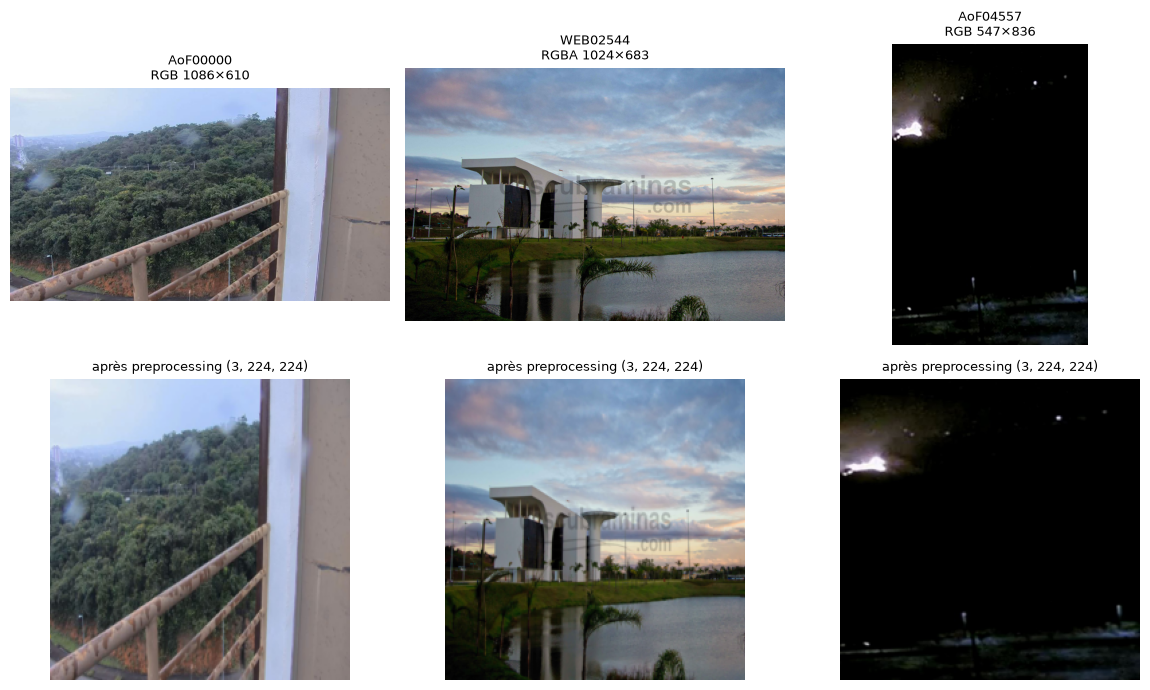

In [ ]:
# Exemples choisis à partir des métadonnées de l'exploration (mode, orientation)
meta = pd.read_csv(METADATA_PATH, usecols=["image_id", "mode", "width", "height"])
ids = [
    meta.loc[meta["mode"] == "RGB", "image_id"].iloc[0],
    meta.loc[meta["mode"] == "RGBA", "image_id"].iloc[0],
    meta.loc[meta["height"] > meta["width"], "image_id"].iloc[0],
]

fig, axes = plt.subplots(2, len(ids), figsize=(4 * len(ids), 7))
for k, image_id in enumerate(ids):
    pos = df_feat.index[df_feat["image_id"] == image_id][0]
    tensor, _ = dataset[pos]
    original = Image.open(ROOT_DIR / df_feat.loc[pos, "path"])
    axes[0, k].imshow(original.convert("RGB"))
    axes[0, k].set_title(f"{image_id}\n{original.mode} {original.size[0]}×{original.size[1]}", fontsize=9)
    # Dénormalisation pour l'affichage : x * std + mean
    shown = tensor.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN
    axes[1, k].imshow(np.clip(shown, 0, 1))
    axes[1, k].set_title(f"après preprocessing {tuple(tensor.shape)}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 12. Chargement de ResNet50 (ImageNet) et suppression de la tête de classification

- Poids `IMAGENET1K_V2` de torchvision (`DEFAULT`), comme dans le P7 : acc@1 80,9 % sur ImageNet
  contre 76,1 % pour `V1` (doc torchvision).
- La couche `fc` (1000 classes ImageNet) est remplacée par `Identity` : la sortie est le vecteur de
  **2048 features** issu de l'average pooling, représentation globale de l'image.
- Tous les poids sont **gelés** : extraction uniquement, aucun entraînement.

In [ ]:
backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2, progress=False)
for param in backbone.parameters():
    param.requires_grad = False          # aucun poids modifié
backbone.fc = nn.Identity()              # sortie = vecteur de 2048 features
backbone = backbone.to(DEVICE).eval()    # eval() : BatchNorm en mode inférence

## 13. Extraction des features

In [ ]:
all_features, all_ids = [], []
t0 = time.time()

with torch.no_grad():                    # pas de gradients : inutile pour l'extraction
    for batch_idx, (images, image_ids) in enumerate(loader):
        features = backbone(images.to(DEVICE, non_blocking=True))   # transfert asynchrone (pin_memory)
        all_features.append(features.cpu().numpy())
        all_ids.extend(image_ids)
        if (batch_idx + 1) % 50 == 0:
            print(f"  batch {batch_idx + 1}/{len(loader)} – {time.time() - t0:.0f} s")

features_matrix = np.concatenate(all_features).astype(np.float32)
print(f"\nExtraction terminée en {time.time() - t0:.0f} s")
print(f"Matrice de features : {features_matrix.shape}")
print(f"Empreinte mémoire   : {features_matrix.nbytes / 1024**2:.0f} Mo (float32)")

  batch 50/337 – 30 s
  batch 100/337 – 57 s
  batch 150/337 – 81 s
  batch 200/337 – 106 s
  batch 250/337 – 133 s
  batch 300/337 – 161 s

Extraction terminée en 179 s
Matrice de features : (21527, 2048)
Empreinte mémoire   : 168 Mo (float32)


## 14. Sauvegarde des features

In [ ]:
assert list(all_ids) == df_feat["image_id"].tolist()   # ordre des lignes = ordre de df_feat

np.save(FEATURES_DIR / "resnet50_features.npy", features_matrix)
df_feat[split_cols].to_csv(FEATURES_DIR / "resnet50_metadata.csv", index=False)
print("Fichiers sauvegardés dans data/processed/features/ :")
print(f"  resnet50_features.npy  -> {features_matrix.shape}")
print(f"  resnet50_metadata.csv  -> {len(df_feat)} lignes (même ordre que la matrice)")

Fichiers sauvegardés dans data/processed/features/ :
  resnet50_features.npy  -> (21527, 2048)
  resnet50_metadata.csv  -> 21527 lignes (même ordre que la matrice)


## 15. Vérification : rechargement et cohérence

In [ ]:
features_check = np.load(FEATURES_DIR / "resnet50_features.npy")
meta_check = pd.read_csv(FEATURES_DIR / "resnet50_metadata.csv")

print(f"Features rechargées : {features_check.shape} | métadonnées : {meta_check.shape}")
print(f"Valeurs NaN / infinies : {(~np.isfinite(features_check)).sum()}")
print(f"Features min / max : {features_check.min():.3f} / {features_check.max():.3f}")
print(f"Vecteurs nuls : {(np.abs(features_check).sum(axis=1) == 0).sum()}")
display(meta_check["final_split"].value_counts().reindex(["train", "val", "test"]).to_frame("images"))

Features rechargées : (21527, 2048) | métadonnées : (21527, 10)
Valeurs NaN / infinies : 0
Features min / max : 0.000 / 15.166
Vecteurs nuls : 0


,images
final_split,
train,13773
val,3448
test,4306


## 16. Conclusions

_Chiffres issus de l'exécution du 13/11/2026 (RTX 5070 Laptop, CUDA)._

**Labels**
- Les 18 boîtes d'aire nulle ne changent aucun label image (0 image modifiée).

**Découpage figé** (`data/processed/splits.csv`)
- **train 13 773 / val 3 448 / test 4 306** (val = 20,0 % du train officiel).
- 9 593 groupes de quasi-doublons dans le train (plus gros : 849 images) ; **0 groupe partagé** entre train et val.
- Stratification respectée : écart ≤ 0,2 point entre train et val sur chaque catégorie ; fumée ≈ 49 % et feu ≈ 27 %
  en train comme en val (test officiel : 48,3 % et 25,9 %).

**Test propre**
- **2 192 images sur 4 306 (50,9 %)** n'ont aucun quasi-doublon (distance ≤ 4) dans le train officiel (train + val).
- Fuite très concentrée sur `AoF` : seulement 124 images `AoF` propres sur 1 661, contre 1 923 `WEB` sur 2 364.
- Le test propre n'a donc **pas la même composition** que le test complet (surtout des images `WEB`) :
  les écarts de score entre les deux mélangeront effet de la fuite et effet de la source → rapporter
  aussi les métriques par source.

**Preprocessing et features**
- Même pipeline fixe pour train, val et test : RGB → 224×224 sans recadrage → normalisation ImageNet.
- PNG / RGBA et images en portrait correctement traités (vérification visuelle section 11).
- Matrice **21 527 × 2048** (ResNet50 `IMAGENET1K_V2` gelé), 168 Mo, aucune valeur NaN / infinie, aucun vecteur nul.
- Extraction sur GPU en **184 s** (décodage JPEG réduit ; 422 s avec décodage complet).

**Suite – analyse non supervisée (`unsupervised_analysis.ipynb`)** : simuler le faible étiquetage dans le train
(sous-ensemble labellisé), puis standardisation,
réduction de dimension et clustering **ajustés sur le train uniquement** pour générer les labels faibles.
L'augmentation des images labellisées (faite dans le notebook de preprocessing du P7) sera faite une fois ce
sous-ensemble défini.